# MNIST. Red neuronal MLP (fully connected) y CNN (Convolutional Neural Network).

Para imagenes, la MLP las aplana por lo que se pierde la estructura espacial. Con CNN esto no pasa (esta especialmente diseñada para imagenes).

MNIST significa Modified NIST: es una versión modificada de los datos de números escritos a mano, con las imágenes recortadas, centradas y reescaladas a 28×28 píxeles en escala de grises. Contiene 60.000 imágenes de entrenamiento y 10.000 de prueba. Es el “Hola mundo” del aprendizaje automático.

Queremos entrenar una red que reciba la imagen de un dígito escrito a mano y diga qué número es (0-9). Esto es un problema de clasificación.

### Importamos los datos:

Usando: cuda
Tamaño: 64 imagenes, 1 canal, 28x28 pixeles torch.Size([64, 1, 28, 28]) torch.Size([64])


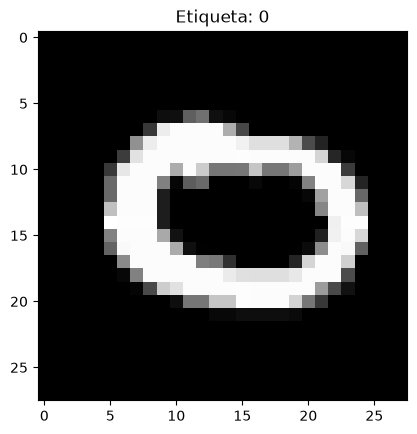

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Usa GPU si hay, si no CPU (MNIST va bien en CPU)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Usando:", device)

# Convierte la imagen a tensor y la normaliza (media y desviación estándar de MNIST)
""" 
- ToTensor() convierte cada píxel de un número entero de 0 a 255 a un decimal entre 0.0 y 1.0.
- Normalize((0.1307,), (0.3081,)) aplica esta fórmula a cada píxel: pixel_nuevo = (pixel - media) / desviación_estándar.
Donde 0.1307 es la media de todos los píxeles de MNIST y 0.3081 su desviación estándar (calculadas previamente sobre el 
conjunto de entrenamiento).
"""
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_data = datasets.MNIST("data", train=True, download=True, transform=transform)
test_data = datasets.MNIST("data", train=False, download=True, transform=transform)

# DataLoader: entrega los datos en lotes (batches)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000)

# Inspeccionamos un lote
"""
1.train_loader es un objeto iterable: un for sobre él devolvería un lote tras otro.
2.iter(train_loader) crea un iterador, es decir, un objeto que “recuerda por dónde va” y puede entregar los lotes de uno en uno.
3.next(...) le pide a ese iterador el siguiente elemento, que al ser la primera vez es el primer lote.
4.Cada lote es una pareja (imágenes, etiquetas), y el desempaquetado images, labels = ... guarda cada parte en su variable.
"""
images, labels = next(iter(train_loader))
print("Tamaño: 64 imagenes, 1 canal, 28x28 pixeles",images.shape, labels.shape)  # torch.Size([64, 1, 28, 28]) torch.Size([64])

plt.imshow(images[0].squeeze(), cmap="gray")
plt.title(f"Etiqueta: {labels[0].item()}")
plt.show()

¿Por qué transformamos los datos? Después de normalizar, los datos tienen media ≈ 0 y desviación ≈ 1. Esto ayuda porque:

El entrenamiento converge más rápido. Con entradas centradas en cero, los gradientes se comportan mejor y el optimizador da pasos más eficaces.
Es más estable. Evita que unas entradas dominen sobre otras por tener una escala mayor (algo muy importante cuando mezclas variables de escalas distintas, como en el Titanic: edad vs. precio del billete).
Funciona mejor con la inicialización de pesos y las funciones de activación, que están diseñadas pensando en entradas de escala similar a 1.

### Definimos el modelo:

La idea:
Imagen [1, 28, 28]

   ↓ Flatten

Vector de 784 (28x28)

   ↓ Linear(784 → 128) + ReLU

Vector de 128

   ↓ Linear(128 → 64) + ReLU

Vector de 64

   ↓ Linear(64 → 10)

10 salidas (logits)

__init__ es donde declaramos las capas. forward es donde decimos cómo fluyen los datos por ellas. No llamas a forward directamente: haces model(x) y PyTorch lo llama por ti (además de ejecutar otras cosas internas).

In [2]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Flatten(),            # [64, 1, 28, 28] -> [64, 784]
            nn.Linear(784, 128),     # capa oculta 1
            nn.ReLU(),
            nn.Linear(128, 64),      # capa oculta 2
            nn.ReLU(),
            nn.Linear(64, 10),       # capa de salida: 10 clases
        )

    def forward(self, x):
        return self.red(x)

model = MLP().to(device)
print(model)

# Comprobamos que funciona con el lote que ya teníamos
salida = model(images.to(device))
print(salida.shape)  # torch.Size([64, 10])

MLP(
  (red): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
torch.Size([64, 10])


El modelo recibe la imagen (o un lote de estas) y devuelve 10 puntuaciones (NO probabilidades sino logits), cada puntuación corresponde a una etiqueta (0,1,2,...,9). estas puntuaciones se transformaran después en probabilidades de dicha etiqueta dada esa imagen.

### Ciclo de entrenamiento:

In [3]:
loss_fn = nn.CrossEntropyLoss() # Recive logits y los transforma a probabilidades ademas de calcular la pérdida
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def entrenar_una_epoca(model, loader, loss_fn, optimizer):
    model.train()                      # modo entrenamiento
    perdida_total = 0

    for batch, (X, y) in enumerate(loader): # Enumeramos los lotes y cargamos las imagenes y etiquetas de cada lote.
        X, y = X.to(device), y.to(device)

        # 1. Forward: predicción
        pred = model(X)                # [64, 10]

        # 2. Pérdida: comparamos predicción con etiquetas reales
        loss = loss_fn(pred, y)

        # 3. Backward: calcular gradientes
        optimizer.zero_grad()          # borra gradientes del lote anterior
        loss.backward()                # calcula gradientes de cada peso

        # 4. Actualizar pesos
        optimizer.step()

        perdida_total += loss.item()
        if batch % 200 == 0:
            print(f"  lote {batch:4d}/{len(loader)}  pérdida: {loss.item():.4f}")

    return perdida_total / len(loader) # La perdida total que ha habido en toda la época / el numero de lotes

### Evaluación del modelo con los datos de test:

Hasta ahora solo hemos mirado la pérdida de entrenamiento, que mide cómo lo hace la red con imágenes que ya ha visto. Ahora vamos a medir lo que realmente importa: la precisión (accuracy) con las 10.000 imágenes de prueba, que la red nunca ha usado para ajustar sus pesos.

- Pérdida: un número útil para el optimizador, pero difícil de interpretar.
- Precisión (accuracy): el porcentaje de imágenes clasificadas correctamente. Es fácil de entender.

In [4]:
def evaluar(model, loader, loss_fn):
    model.eval()                       # modo evaluación
    perdida_total = 0
    correctas = 0

    with torch.no_grad():              # no calcula gradientes (no alteramos los parámetros de la red)
        for X, y in loader: # para todos los lotes de las 10.000 imagenes de prueba (10 lotes)
            X, y = X.to(device), y.to(device)

            pred = model(X)            # [1000, 10] --> UN lote de prueba
            perdida_total += loss_fn(pred, y).item()
            correctas += (pred.argmax(dim=1) == y).sum().item() # respuestas correctas del lote de 1000 imagenes

    perdida_media = perdida_total / len(loader)
    precision = correctas / len(loader.dataset) # Numero de correctas en todo el dataset / el tamaño del dataset
    return perdida_media, precision


# Entreno al modelo ya con la evaluacción en cada época.
"""
OJO: puedo hacer este ciclo porque ya he definido el modelo de 'model' y el optimizador en optimizer, sin esto
no podría hacerlo así. (Cada vez que se evalue o entrene el modelo hay que definirlo a el y al optimizador).
"""
historial = {"train_loss": [], "test_loss": [], "test_acc": []}

epocas = 5
for epoca in range(epocas):
    print(f"Época {epoca + 1}/{epocas}")
    perdida_train = entrenar_una_epoca(model, train_loader, loss_fn, optimizer)
    perdida_test, precision_test = evaluar(model, test_loader, loss_fn)

    historial["train_loss"].append(perdida_train)
    historial["test_loss"].append(perdida_test)
    historial["test_acc"].append(precision_test)

    print(f"  -> pérdida train: {perdida_train:.4f} | "
          f"pérdida test: {perdida_test:.4f} | "
          f"precisión test: {precision_test:.2%}\n")

Época 1/5
  lote    0/938  pérdida: 2.3153
  lote  200/938  pérdida: 0.1776
  lote  400/938  pérdida: 0.1727
  lote  600/938  pérdida: 0.1171
  lote  800/938  pérdida: 0.0468
  -> pérdida train: 0.2673 | pérdida test: 0.1513 | precisión test: 95.25%

Época 2/5
  lote    0/938  pérdida: 0.2213
  lote  200/938  pérdida: 0.1243
  lote  400/938  pérdida: 0.0846
  lote  600/938  pérdida: 0.0605
  lote  800/938  pérdida: 0.0923
  -> pérdida train: 0.1149 | pérdida test: 0.0977 | precisión test: 96.76%

Época 3/5
  lote    0/938  pérdida: 0.1252
  lote  200/938  pérdida: 0.1498
  lote  400/938  pérdida: 0.1083
  lote  600/938  pérdida: 0.0395
  lote  800/938  pérdida: 0.0555
  -> pérdida train: 0.0803 | pérdida test: 0.0911 | precisión test: 97.28%

Época 4/5
  lote    0/938  pérdida: 0.0204
  lote  200/938  pérdida: 0.0100
  lote  400/938  pérdida: 0.0905
  lote  600/938  pérdida: 0.0907
  lote  800/938  pérdida: 0.0163
  -> pérdida train: 0.0622 | pérdida test: 0.0796 | precisión test: 97.5

### Cómo interpretar los resultados:

- Compara la pérdida de train con la de test:

Ambas bajan juntas: la red está aprendiendo y generaliza bien.
Train baja pero test se estanca o sube: sobreajuste (overfitting). La red memoriza el entrenamiento en vez de aprender patrones generales. Con más épocas probablemente lo verás en este MLP: la pérdida de train seguirá bajando mientras la de test deja de mejorar.

- Ver los errores (opcional pero muy instructivo)

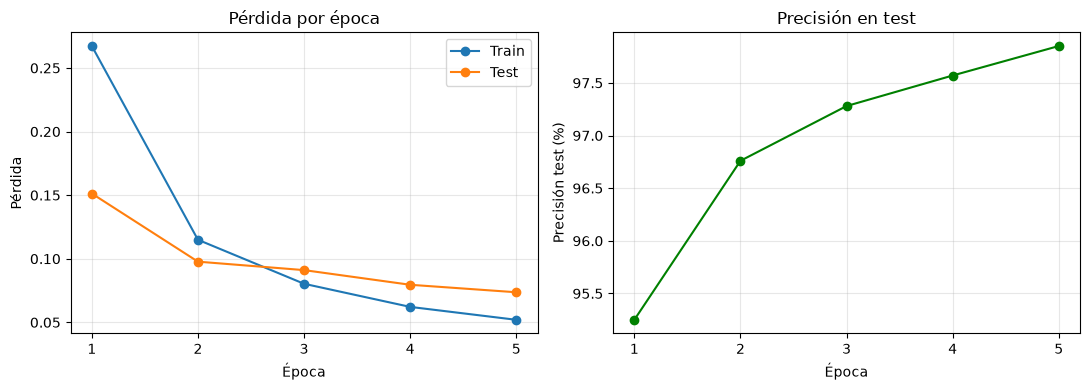

tensor([ 92, 104, 149, 247, 321, 381, 445, 449])


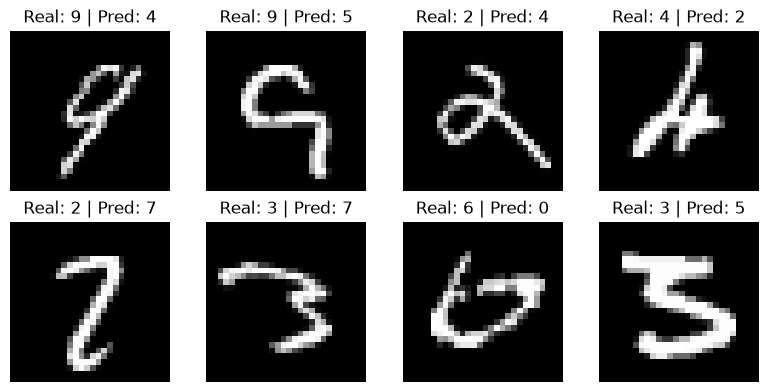

In [5]:
def dibujar_historial(historial):
    epocas = range(1, len(historial["train_loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    # Pérdidas
    ax1.plot(epocas, historial["train_loss"], marker="o", label="Train")
    ax1.plot(epocas, historial["test_loss"], marker="o", label="Test")
    ax1.set_xlabel("Época")
    ax1.set_ylabel("Pérdida")
    ax1.set_title("Pérdida por época")
    ax1.set_xticks(list(epocas))
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Precisión
    ax2.plot(epocas, [a * 100 for a in historial["test_acc"]], marker="o", color="green")
    ax2.set_xlabel("Época")
    ax2.set_ylabel("Precisión test (%)")
    ax2.set_title("Precisión en test")
    ax2.set_xticks(list(epocas))
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

dibujar_historial(historial)

#========================================================

model.eval()
X, y = next(iter(test_loader)) # Un lote de test!
with torch.no_grad():
    pred = model(X.to(device)).argmax(dim=1).cpu() # Respuestas con argmax sobre las probs (10 probabilidades) para
                                                   # qudarnos con la respuesta más probable como respuesta final
                                                   # dim(pred) = tensor([1000,1]) 1000 imagenes, una prediccion por cada
errores = (pred != y).nonzero().squeeze()[:8]
print(errores)

fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for ax, i in zip(axes.flat, errores):
    ax.imshow(X[i].squeeze(), cmap="gray")
    ax.set_title(f"Real: {y[i]} | Pred: {pred[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

Este MLP ya ha dado casi todo lo que puede dar. Entrenar más épocas haría que la pérdida de train siguiera bajando hacia 0, pero la de test no mejoraría e incluso empeoraría. Es la limitación que vimos al principio: al aplanar la imagen, el MLP no entiende la estructura espacial, y a partir de cierto punto solo puede mejorar memorizando.

## Misma red pero con CNN
Cambiamos el medelo, los demás se queda igual.
Imagen [1, 28, 28]

   ↓ Conv2d(1 → 16, 3×3) + ReLU      → [16, 28, 28]

   ↓ MaxPool2d(2)                     → [16, 14, 14]

   ↓ Conv2d(16 → 32, 3×3) + ReLU     → [32, 14, 14]

   ↓ MaxPool2d(2)                     → [32, 7, 7]

   ↓ Flatten                          → [1568]

   ↓ Linear(1568 → 64) + ReLU         → [64]

   ↓ Linear(64 → 10)                  → [10] (logits)

La primera mitad (convoluciones) extrae patrones, y la segunda (capas lineales) clasifica usando esos patrones.
¿Qué hace cada cosa?:
1. Conv2d(1,16,kernel_size=3,padding=1):
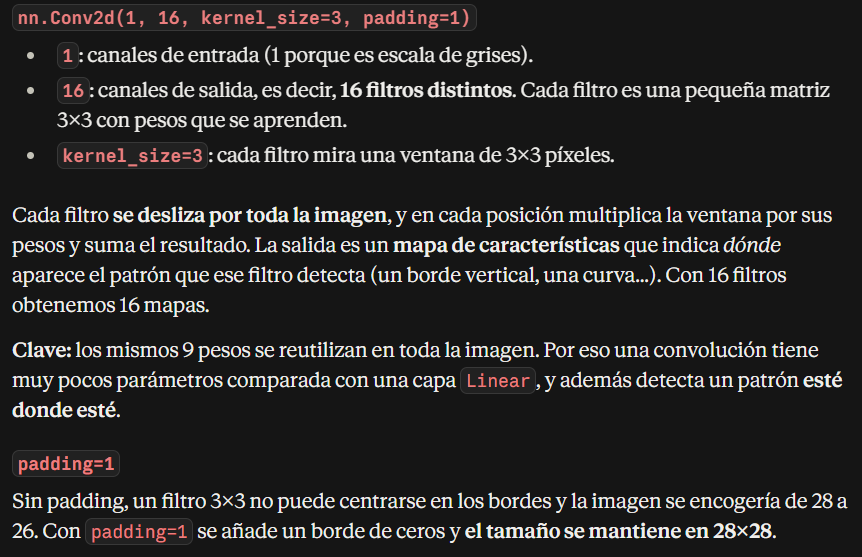
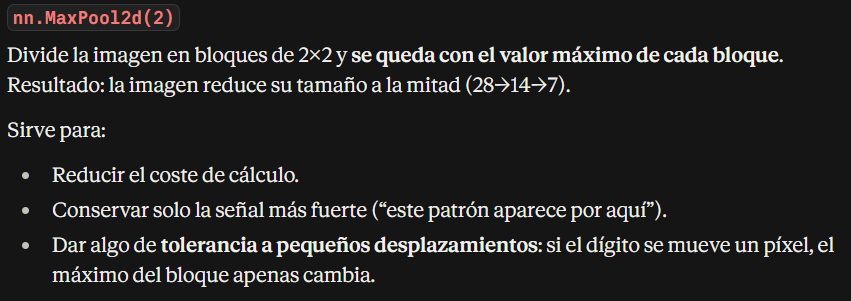

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
Parámetros: 105866
torch.Size([64, 10])
Época 1/5
  lote    0/938  pérdida: 2.2911
  lote  200/938  pérdida: 0.2860
  lote  400/938  pérdida: 0.0928
  lote  600/938  pérdida: 0.0714
  lote  800/938  pérdida: 0.0235
  -> pérdida train: 0.1713 | pérdida test: 0.0510 | precisión test: 98.24%

Época 2/5
  lote    0/938  pérdida: 0.0734
  lote  200/938  pérdida: 0.0331
  lote  400/938  pérdida: 0.0741
  

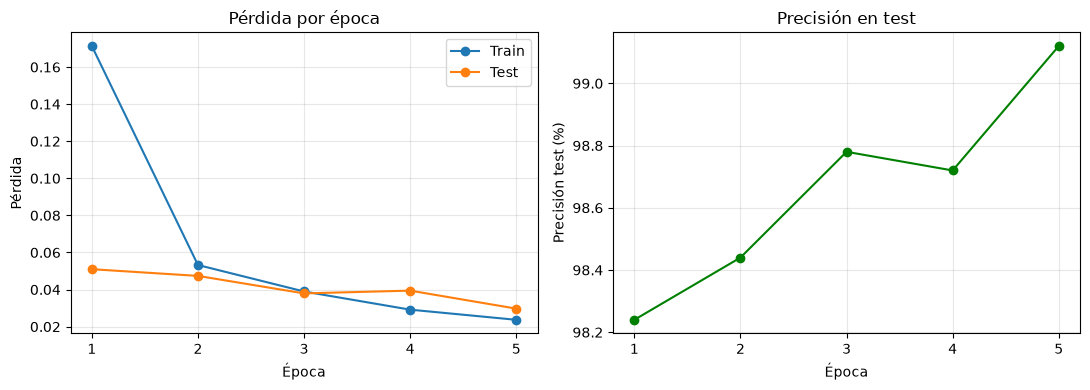

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),   # [B=batch,1,28,28] -> [B,16,28,28]
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> [B,16,14,14]

            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # -> [B,32,14,14]
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> [B,32,7,7]
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # -> [B,1568]
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CNN().to(device)
print(model)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

# Comprobamos las formas con un lote
print(model(images.to(device)).shape)  # torch.Size([64, 10])

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

historial_cnn = {"train_loss": [], "test_loss": [], "test_acc": []}

epocas = 5
for epoca in range(epocas):
    print(f"Época {epoca + 1}/{epocas}")
    perdida_train = entrenar_una_epoca(model, train_loader, loss_fn, optimizer)
    perdida_test, precision_test = evaluar(model, test_loader, loss_fn)

    historial_cnn["train_loss"].append(perdida_train)
    historial_cnn["test_loss"].append(perdida_test)
    historial_cnn["test_acc"].append(precision_test)

    print(f"  -> pérdida train: {perdida_train:.4f} | "
          f"pérdida test: {perdida_test:.4f} | "
          f"precisión test: {precision_test:.2%}\n")

dibujar_historial(historial_cnn)

## Mejoras para la CNN.
Ya hemos visto wue CNN es mejor que MLP ya que aprovacha la estructura espacial de la imagen. A continuación vemos que mejoras podemos hacerle a esta red CNN.

### 1. Dropout + BatchNorm (regularización y estabilidad).
- BatchNorm (nn.BatchNorm2d): normaliza las salidas de una capa, igual que normalizamos las imágenes al principio, pero dentro de la red, en cada lote. Esto hace el entrenamiento más estable y rápido, y permite usar learning rates mayores. Tiene además dos parámetros aprendibles (escala y desplazamiento) para que la red pueda deshacer la normalización si le conviene.

- Dropout (nn.Dropout): durante el entrenamiento apaga aleatoriamente un porcentaje de neuronas en cada paso (por ejemplo, el 30 %). Así la red no puede depender de una neurona concreta y está obligada a aprender patrones más robustos. Es una forma directa de combatir el sobreajuste que vimos en las gráficas.

Dónde se colocan:
- BatchNorm2d va después de la convolución y antes de ReLU (es lo más habitual).
- Dropout va en la parte de clasificación, normalmente antes de la capa lineal final.

Aquí es donde model.train() y model.eval() cobran sentido

Te dije antes que esas llamadas eran “buena costumbre” aunque no hicieran nada. Ahora sí importan, porque estas dos capas se comportan distinto según el modo:

- Dropout: en train() apaga neuronas al azar; en eval() no apaga ninguna y usa toda la red.
- BatchNorm: en train() usa la media y desviación del lote actual (y va guardando una media móvil); en eval() usa esas medias acumuladas, para que la predicción de una imagen no dependa de qué otras imágenes vengan en el lote.

Época 1/8
  lote    0/938  pérdida: 2.4313
  lote  200/938  pérdida: 0.1215
  lote  400/938  pérdida: 0.1794
  lote  600/938  pérdida: 0.1936
  lote  800/938  pérdida: 0.1264
  -> pérdida train: 0.2207 | pérdida test: 0.0477 | precisión test: 98.46%

Época 2/8
  lote    0/938  pérdida: 0.1927
  lote  200/938  pérdida: 0.1162
  lote  400/938  pérdida: 0.1588
  lote  600/938  pérdida: 0.0197
  lote  800/938  pérdida: 0.0183
  -> pérdida train: 0.0883 | pérdida test: 0.0389 | precisión test: 98.70%

Época 3/8
  lote    0/938  pérdida: 0.0185
  lote  200/938  pérdida: 0.1993
  lote  400/938  pérdida: 0.0384
  lote  600/938  pérdida: 0.0360
  lote  800/938  pérdida: 0.0185
  -> pérdida train: 0.0708 | pérdida test: 0.0386 | precisión test: 98.73%

Época 4/8
  lote    0/938  pérdida: 0.0387
  lote  200/938  pérdida: 0.0425
  lote  400/938  pérdida: 0.0810
  lote  600/938  pérdida: 0.0507
  lote  800/938  pérdida: 0.0118
  -> pérdida train: 0.0564 | pérdida test: 0.0368 | precisión test: 98.7

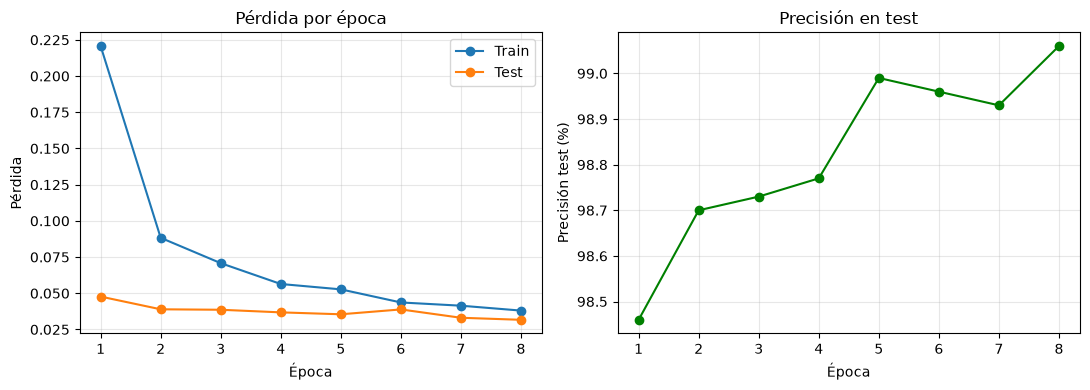

In [7]:
class CNN2(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CNN2().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

historial_cnn2 = {"train_loss": [], "test_loss": [], "test_acc": []}

epocas = 8 # 8 para que se vea mejor el efecto de la regularización.
for epoca in range(epocas):
    print(f"Época {epoca + 1}/{epocas}")
    perdida_train = entrenar_una_epoca(model, train_loader, loss_fn, optimizer)
    perdida_test, precision_test = evaluar(model, test_loader, loss_fn)

    historial_cnn2["train_loss"].append(perdida_train)
    historial_cnn2["test_loss"].append(perdida_test)
    historial_cnn2["test_acc"].append(precision_test)

    print(f"  -> pérdida train: {perdida_train:.4f} | "
          f"pérdida test: {perdida_test:.4f} | "
          f"precisión test: {precision_test:.2%}\n")

dibujar_historial(historial_cnn2)

### 2. Data augmentation.

La idea:

La red solo ve las 60.000 imágenes originales, siempre iguales. Data augmentation consiste en aplicar pequeñas transformaciones aleatorias a cada imagen cada vez que se carga: girarla unos grados, desplazarla un poco, escalarla... De esta forma, en cada época la red ve versiones ligeramente distintas de los mismos dígitos.

Esto es como tener muchos más datos sin recopilar ninguno, y combate el sobreajuste porque la red no puede memorizar píxeles exactos: tiene que aprender la forma del dígito.

*Regla importante:* solo en entrenamiento. El augmentation se aplica únicamente al conjunto de entrenamiento. El de test debe quedarse intacto, porque queremos medir el rendimiento sobre imágenes reales y sin alterar. Por eso necesitamos dos transformaciones distintas.

In [8]:
"""
Re-hacemos los loaders.
"""

# Test: solo convertir y normalizar (sin aleatoriedad)
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

# Train: añadimos transformaciones aleatorias ANTES de ToTensor
transform_train = transforms.Compose([
    transforms.RandomAffine(
        degrees=10,             # rotación aleatoria entre -10° y +10°
        translate=(0.1, 0.1),   # desplazamiento de hasta un 10 % en x e y
        scale=(0.9, 1.1),       # zoom entre 90 % y 110 %
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_data_aug = datasets.MNIST("data", train=True, download=True, transform=transform_train)
test_data = datasets.MNIST("data", train=False, download=True, transform=transform_test)

train_loader_aug = DataLoader(train_data_aug, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000)

Entrenamos el mismo modelo CNN2, pero con los nuevos loaders.

Época 1/8
  lote    0/938  pérdida: 2.3163
  lote  200/938  pérdida: 0.3248
  lote  400/938  pérdida: 0.1710
  lote  600/938  pérdida: 0.3028
  lote  800/938  pérdida: 0.2185
  -> pérdida train: 0.4040 | pérdida test: 0.0534 | precisión test: 98.37%

Época 2/8
  lote    0/938  pérdida: 0.1374
  lote  200/938  pérdida: 0.0987
  lote  400/938  pérdida: 0.0635
  lote  600/938  pérdida: 0.1205
  lote  800/938  pérdida: 0.1354
  -> pérdida train: 0.1903 | pérdida test: 0.0412 | precisión test: 98.67%

Época 3/8
  lote    0/938  pérdida: 0.1016
  lote  200/938  pérdida: 0.1541
  lote  400/938  pérdida: 0.1953
  lote  600/938  pérdida: 0.2522
  lote  800/938  pérdida: 0.2360
  -> pérdida train: 0.1605 | pérdida test: 0.0332 | precisión test: 99.03%

Época 4/8
  lote    0/938  pérdida: 0.1693
  lote  200/938  pérdida: 0.1315
  lote  400/938  pérdida: 0.2219
  lote  600/938  pérdida: 0.1374
  lote  800/938  pérdida: 0.3101
  -> pérdida train: 0.1380 | pérdida test: 0.0377 | precisión test: 98.7

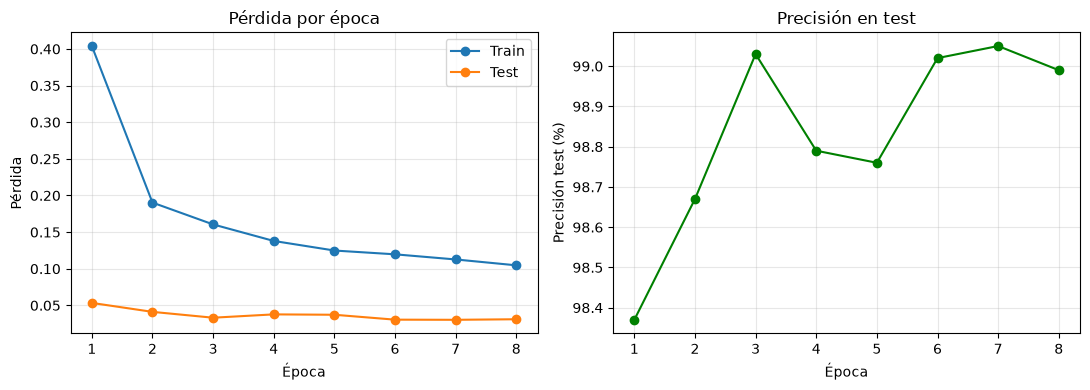

In [9]:
model = CNN2().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

historial_aug = {"train_loss": [], "test_loss": [], "test_acc": []}

epocas = 8
for epoca in range(epocas):
    print(f"Época {epoca + 1}/{epocas}")
    perdida_train = entrenar_una_epoca(model, train_loader_aug, loss_fn, optimizer)
    perdida_test, precision_test = evaluar(model, test_loader, loss_fn)

    historial_aug["train_loss"].append(perdida_train)
    historial_aug["test_loss"].append(perdida_test)
    historial_aug["test_acc"].append(precision_test)

    print(f"  -> pérdida train: {perdida_train:.4f} | "
          f"pérdida test: {perdida_test:.4f} | "
          f"precisión test: {precision_test:.2%}\n")

dibujar_historial(historial_aug)

Imagenes transformadas:

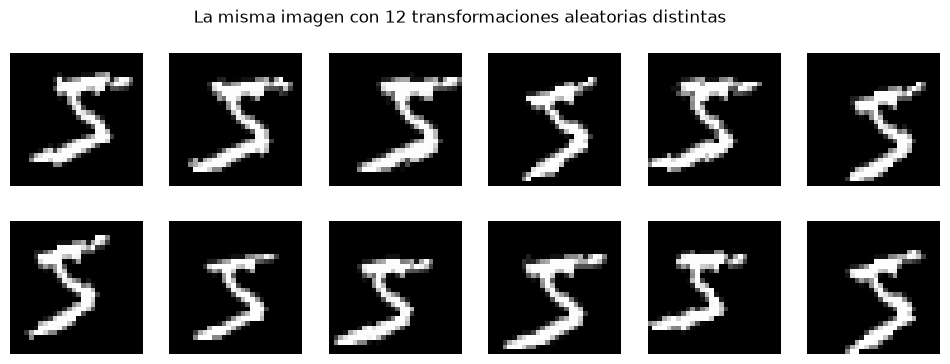

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for ax in axes.flat:
    img, label = train_data_aug[0]   # siempre la misma imagen original
    ax.imshow(img.squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("La misma imagen con 12 transformaciones aleatorias distintas")
plt.show()

**El orden importa:** RandomAffine trabaja con la imagen original (tipo PIL), así que va antes de ToTensor(). Normalize va siempre al final.

Cuidado: *no todo augmentation vale*

Hay que elegir transformaciones que conserven la etiqueta. En MNIST, un giro de 10° sigue siendo el mismo dígito. Pero:

- Volteo horizontal (RandomHorizontalFlip): mala idea aquí, porque un 2 volteado ya no es un 2.
- Rotaciones grandes (por ejemplo, 180°): un 6 se convertiría en un 9, con la etiqueta equivocada.

En perros vs. gatos, en cambio, el volteo horizontal sí es válido. **La regla es: ¿una persona seguiría viendo la misma clase?**

### 3. Visualizar los filtros para ver qué ha aprendido realmente la CNN.

Hasta ahora la CNN ha sido una caja negra: sabemos que acierta, pero no qué ha aprendido. Vamos a mirar dentro de dos maneras:

- Los filtros de la primera capa: los 16 pesos 3×3 que la red ha aprendido. Muestran qué patrones busca.
- Los mapas de características: lo que produce cada filtro al aplicarse a una imagen concreta. Muestran dónde encuentra esos patrones.

Usaremos el modelo CNN2 que acabas de entrenar (con o sin augmentation, da igual).

torch.Size([16, 1, 3, 3])


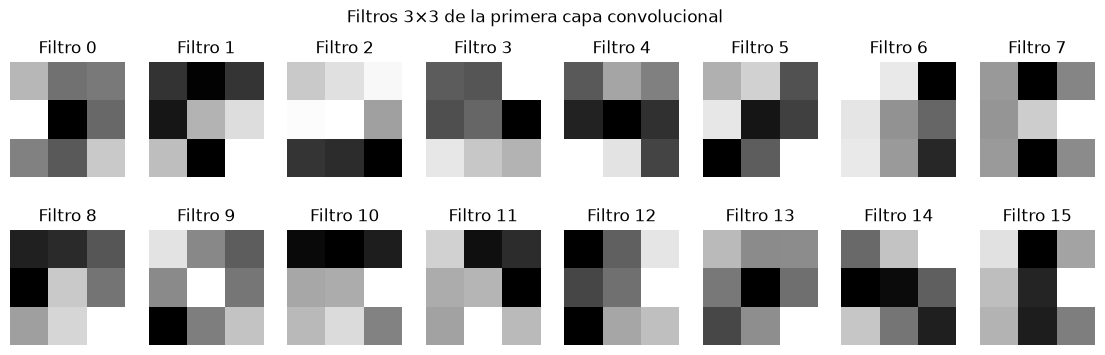

In [11]:
""" Parte 1: visualizar los filtros """

# Pesos de la primera convolución: forma [16, 1, 3, 3]
pesos = model.features[0].weight.detach().cpu()
print(pesos.shape)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(pesos[i, 0], cmap="gray")
    ax.set_title(f"Filtro {i}")
    ax.axis("off")
plt.suptitle("Filtros 3×3 de la primera capa convolucional")
plt.show()

Cómo leerlos

Cada filtro es una cuadrícula de 3×3 en la que los píxeles claros son pesos positivos y los oscuros negativos. El filtro responde con fuerza cuando la imagen coincide con ese patrón:

* Una columna clara a la derecha y oscura a la izquierda: detecta un borde vertical (de oscuro a claro).
* Una fila clara arriba y oscura abajo: detecta un borde horizontal.
* Diagonales: detectan trazos inclinados.

Con solo 3×3 píxeles los filtros se ven muy toscos, y algunos pueden parecer ruido. Es normal. Aun así, deberías reconocer varios que parecen detectores de bordes en distintas orientaciones.

model.features[0] es la primera capa de features, es decir, el Conv2d(1, 16). El .detach() desconecta el tensor del grafo de gradientes para poder usarlo con matplotlib.

Etiqueta real: 7


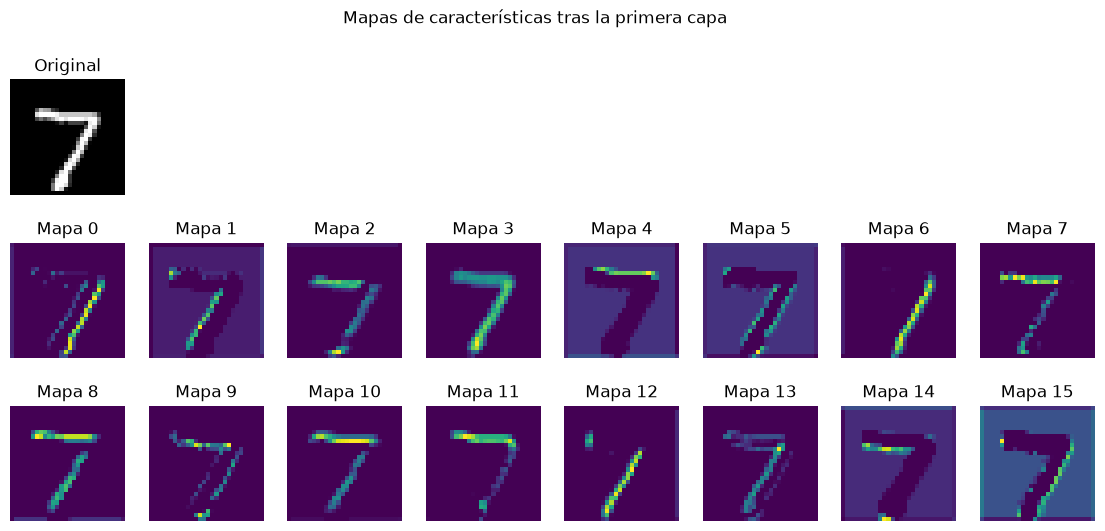

In [12]:
""" Parte 2: visualizar los mapas de características """

model.eval()

# Cogemos una imagen de test
img, label = test_data[0]
print("Etiqueta real:", label)

with torch.no_grad():
    x = img.unsqueeze(0).to(device)          # [1, 1, 28, 28]
    # Salida de Conv -> BatchNorm -> ReLU (las 3 primeras capas)
    mapas = model.features[:3](x).squeeze(0).cpu()   # [16, 28, 28]

fig, axes = plt.subplots(3, 8, figsize=(14, 6))

axes[0, 0].imshow(img.squeeze(), cmap="gray")
axes[0, 0].set_title("Original")

for ax in axes.flat[1:]:
    ax.axis("off")
axes[0, 0].axis("off")

for i in range(16):
    ax = axes.flat[i + 8]
    ax.imshow(mapas[i], cmap="viridis")
    ax.set_title(f"Mapa {i}")
    ax.axis("off")

plt.suptitle("Mapas de características tras la primera capa")
plt.show()

Cómo leerlos

Cada mapa es una imagen de 28×28 donde las zonas brillantes indican que ese filtro encontró su patrón ahí. Verás por ejemplo:

* Un mapa que se ilumina solo en los trazos verticales del dígito.
* Otro que resalta los trazos horizontales o las curvas.
* Alguno casi apagado: ese filtro no encuentra su patrón en esta imagen concreta (gracias a ReLU, lo que no coincide queda en 0).

Qué detalles merecen explicación

- img.unsqueeze(0): la red espera un lote, es decir, [B, 1, 28, 28]. Una imagen suelta es [1, 28, 28], así que añadimos una dimensión de lote de tamaño 1.

- model.features[:3]: al ser un nn.Sequential, se puede cortar como una lista. Así ejecutamos solo las tres primeras capas (Conv, BatchNorm, ReLU) y obtenemos la salida intermedia. Es una técnica muy útil para depurar o extraer características.

- .squeeze(0): quita la dimensión de lote para quedarnos con [16, 28, 28].